In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
import sys
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT = "/content/drive/MyDrive/simuteh-2330511089-"
SRC = os.path.join(PROJECT, "src")
DATA = os.path.join(PROJECT, "data", "sintetis")
HASIL = os.path.join(PROJECT, "hasil")

os.makedirs(HASIL, exist_ok=True)
sys.path.insert(0, SRC)

if "utils_cv" in sys.modules:
    del sys.modules["utils_cv"]

from utils_cv import baca, statistik, kontras_bercak

print("Persiapan B3 berhasil.")
print("Data:", DATA)
print("Hasil:", HASIL)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Persiapan B3 berhasil.
Data: /content/drive/MyDrive/simuteh-2330511089-/data/sintetis
Hasil: /content/drive/MyDrive/simuteh-2330511089-/hasil


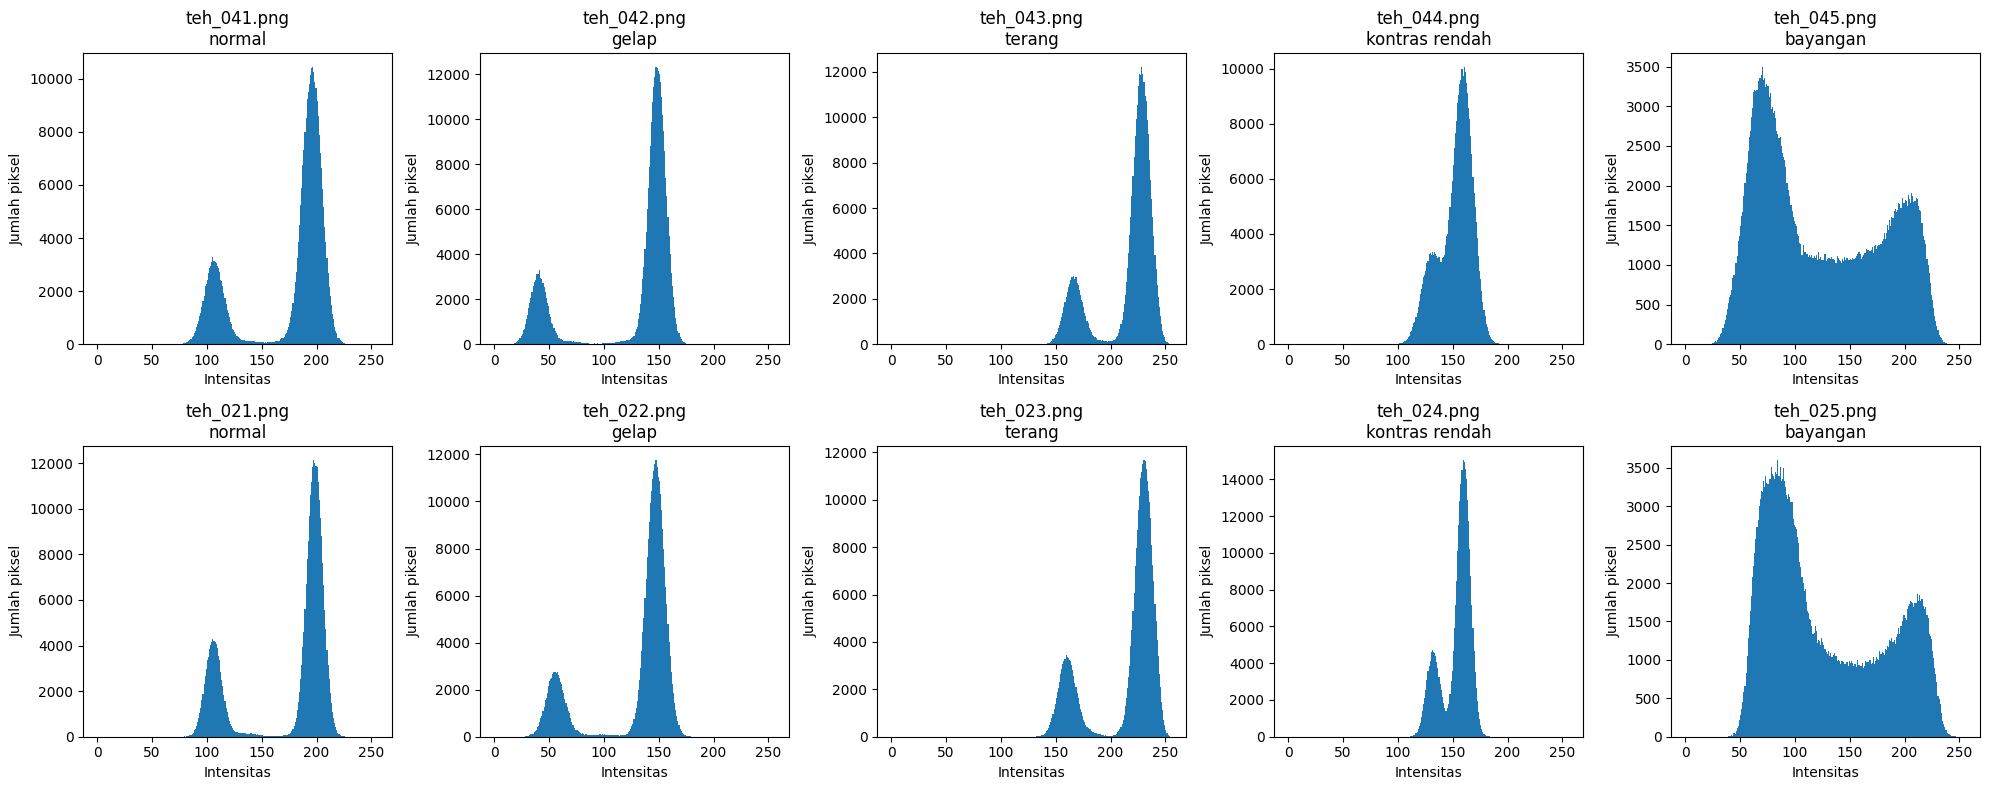

,Citra,Kondisi,Rerata,Simpangan baku,Min,Maks,% gelap,% terang
0,teh_041.png,normal,174.0,38.7,65,238,0.0,9.6
1,teh_042.png,gelap,125.7,44.1,9,183,17.6,0.0
2,teh_043.png,terang,215.1,26.0,127,254,0.0,78.9
3,teh_044.png,kontras rendah,152.0,15.5,90,207,0.0,0.0
4,teh_045.png,bayangan,122.5,55.9,19,242,4.0,9.8
5,teh_021.png,normal,173.1,41.3,72,235,0.0,10.9
6,teh_022.png,gelap,128.8,37.0,15,183,4.6,0.0
7,teh_023.png,terang,213.7,30.4,125,255,0.0,76.4
8,teh_024.png,kontras rendah,152.9,13.3,108,187,0.0,0.0
9,teh_025.png,bayangan,126.9,53.4,36,246,0.2,12.6


In [2]:
kelompok = {
    "berat": [
        "teh_041.png", "teh_042.png", "teh_043.png",
        "teh_044.png", "teh_045.png"
    ],
    "ringan": [
        "teh_021.png", "teh_022.png", "teh_023.png",
        "teh_024.png", "teh_025.png"
    ]
}

nama_kondisi = {
    "teh_041.png": "normal",
    "teh_042.png": "gelap",
    "teh_043.png": "terang",
    "teh_044.png": "kontras rendah",
    "teh_045.png": "bayangan",
    "teh_021.png": "normal",
    "teh_022.png": "gelap",
    "teh_023.png": "terang",
    "teh_024.png": "kontras rendah",
    "teh_025.png": "bayangan"
}

semua_nama = kelompok["berat"] + kelompok["ringan"]
baris_stat = []

fig, axes = plt.subplots(2, 5, figsize=(20, 8))

for i, nama in enumerate(semua_nama):
    img = baca(os.path.join(DATA, "citra", nama))
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    st = statistik(gray)
    baris_stat.append({
        "Citra": nama,
        "Kondisi": nama_kondisi[nama],
        "Rerata": st["rerata"],
        "Simpangan baku": st["simpangan_baku"],
        "Min": st["min"],
        "Maks": st["maks"],
        "% gelap": st["persen_gelap"],
        "% terang": st["persen_terang"]
    })

    ax = axes.flat[i]
    ax.hist(gray.ravel(), bins=256, range=(0, 256))
    ax.set_title(f"{nama}\n{nama_kondisi[nama]}")
    ax.set_xlabel("Intensitas")
    ax.set_ylabel("Jumlah piksel")

plt.tight_layout()
plt.savefig(
    os.path.join(HASIL, "b3_histogram_10citra.png"),
    dpi=150, bbox_inches="tight"
)
plt.show()

tabel_stat = pd.DataFrame(baris_stat)
display(tabel_stat)

tabel_stat.to_csv(
    os.path.join(HASIL, "b3_tabel9_statistik.csv"),
    index=False
)

asli       KB=2.19 | sigma=55.9
negatif    KB=2.19 | sigma=55.9
cerah+50   KB=2.19 | sigma=54.4
kontras    KB=2.19 | sigma=79.2
regang     KB=2.28 | sigma=80.6
gamma0.5   KB=1.84 | sigma=40.7
gamma1.8   KB=2.90 | sigma=59.4
ekualisasi KB=1.57 | sigma=73.4
CLAHE      KB=2.25 | sigma=47.0


,Metode,KB,Simpangan baku
0,asli,2.19,55.9
1,negatif,2.19,55.9
2,cerah+50,2.19,54.4
3,kontras,2.19,79.2
4,regang,2.28,80.6
5,gamma0.5,1.84,40.7
6,gamma1.8,2.90,59.4
7,ekualisasi,1.57,73.4
8,CLAHE,2.25,47.0


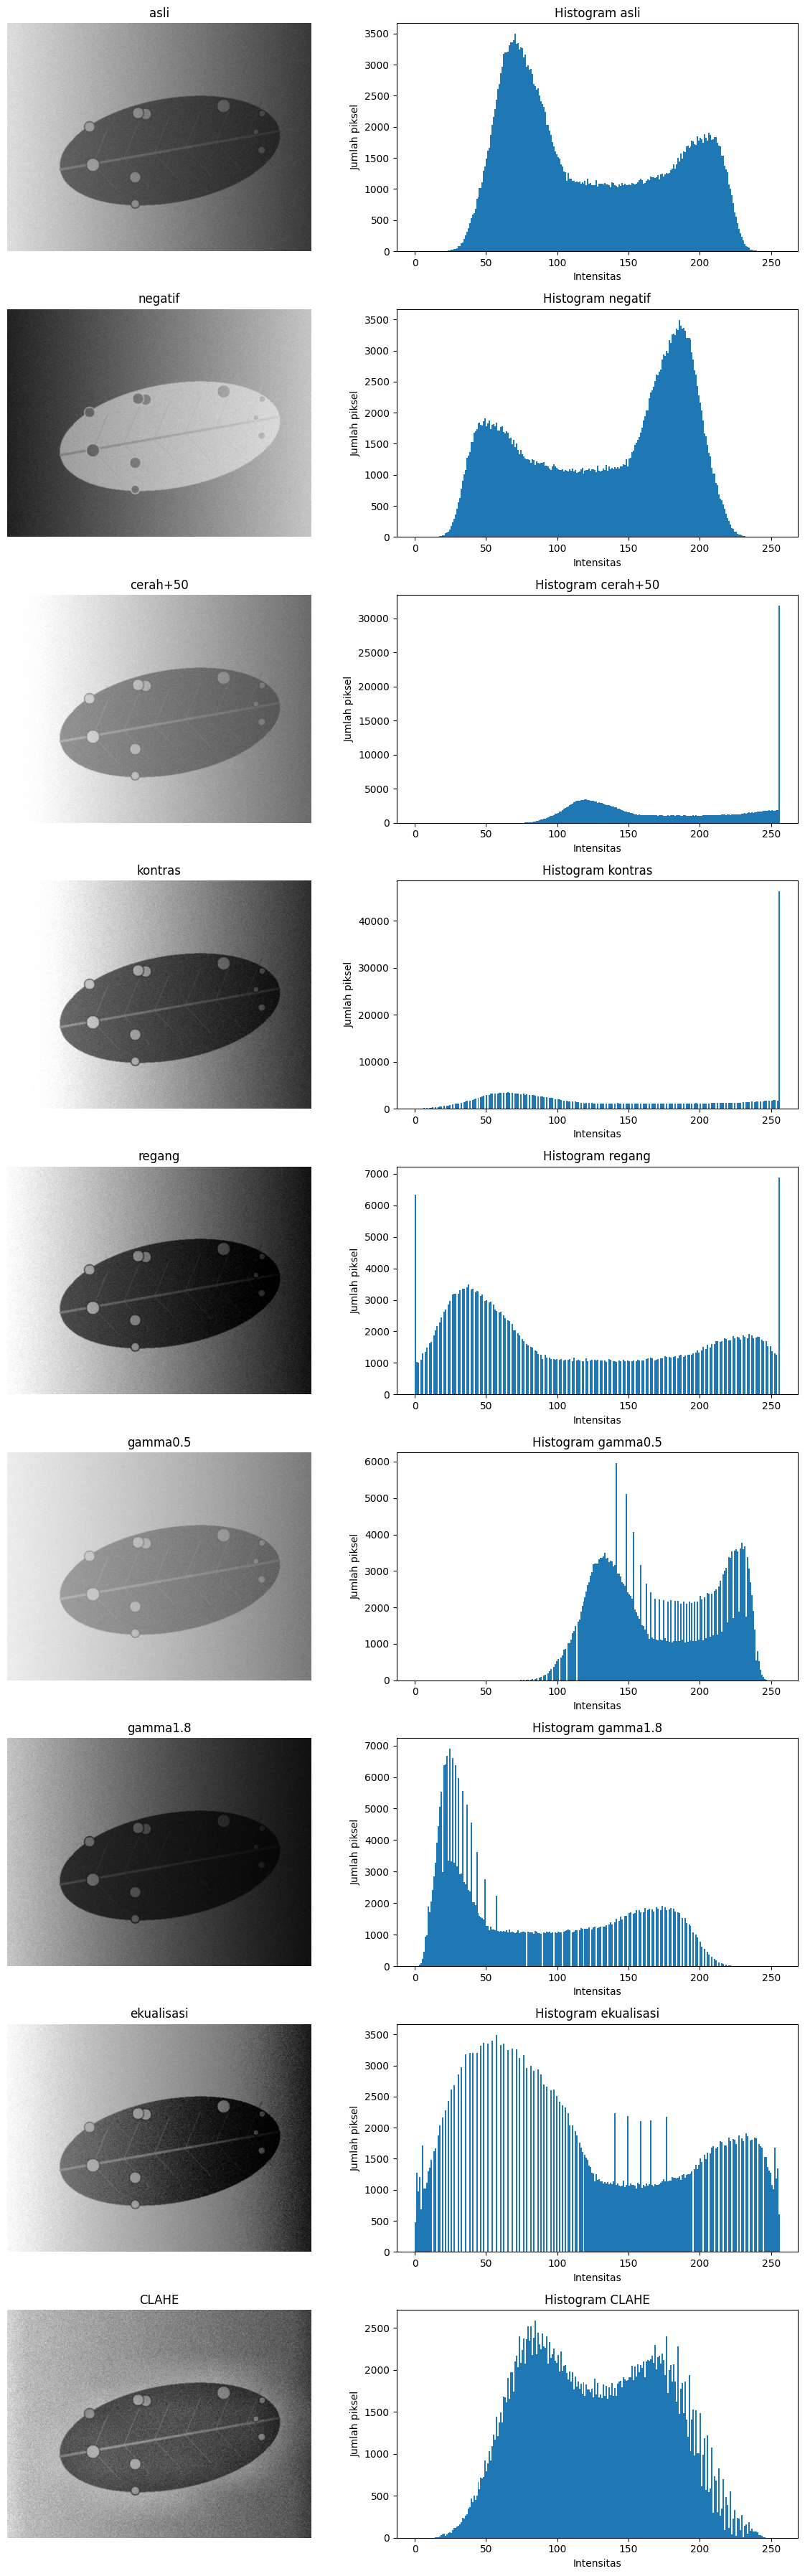

In [3]:
nama = "teh_045.png"

img = baca(os.path.join(DATA, "citra", nama))
md = cv2.imread(os.path.join(DATA, "mask_daun", nama), 0)
mb = cv2.imread(os.path.join(DATA, "mask_bercak", nama), 0)

if md is None or mb is None:
    raise FileNotFoundError("Masker daun/bercak tidak ditemukan.")

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

def gamma_lut(gamma):
    nilai = 255 * (np.arange(256) / 255.0) ** gamma
    return np.clip(nilai, 0, 255).astype(np.uint8)

rmin, rmax = np.percentile(gray, (2, 98))

if rmax <= rmin:
    regang = gray.copy()
else:
    regang = np.clip(
        (gray.astype(np.float32) - rmin) / (rmax - rmin) * 255,
        0, 255
    ).astype(np.uint8)

hasil = {
    "asli": gray,
    "negatif": 255 - gray,
    "cerah+50": cv2.add(gray, 50),
    "kontras": cv2.convertScaleAbs(gray, alpha=1.5, beta=-40),
    "regang": regang,
    "gamma0.5": cv2.LUT(gray, gamma_lut(0.5)),
    "gamma1.8": cv2.LUT(gray, gamma_lut(1.8)),
    "ekualisasi": cv2.equalizeHist(gray),
    "CLAHE": cv2.createCLAHE(
        clipLimit=2.0, tileGridSize=(8, 8)
    ).apply(gray)
}

baris = []

for nm, c in hasil.items():
    kb = kontras_bercak(c, md, mb)
    sigma = float(c.std())

    baris.append({
        "Metode": nm,
        "KB": round(kb, 2),
        "Simpangan baku": round(sigma, 1)
    })

    print(f"{nm:10s} KB={kb:.2f} | sigma={sigma:.1f}")

tabel10 = pd.DataFrame(baris)
display(tabel10)

tabel10.to_csv(
    os.path.join(HASIL, "b3_tabel10_perbaikan.csv"),
    index=False
)

# Panel citra dan histogram untuk setiap metode
fig, axes = plt.subplots(len(hasil), 2, figsize=(12, 4 * len(hasil)))

for i, (nm, c) in enumerate(hasil.items()):
    axes[i, 0].imshow(c, cmap="gray", vmin=0, vmax=255)
    axes[i, 0].set_title(nm)
    axes[i, 0].axis("off")

    axes[i, 1].hist(c.ravel(), bins=256, range=(0, 256))
    axes[i, 1].set_title(f"Histogram {nm}")
    axes[i, 1].set_xlabel("Intensitas")
    axes[i, 1].set_ylabel("Jumlah piksel")

plt.tight_layout()
plt.savefig(
    os.path.join(HASIL, "b3_perbandingan_perbaikan.png"),
    dpi=150, bbox_inches="tight"
)
plt.show()

In [4]:
baris_clahe = []

for clip in [1.0, 2.0, 4.0]:
    for tile in [4, 8, 16]:
        c = cv2.createCLAHE(
            clipLimit=clip,
            tileGridSize=(tile, tile)
        ).apply(gray)

        kb = kontras_bercak(c, md, mb)

        baris_clahe.append({
            "clipLimit": clip,
            "tileGridSize": tile,
            "KB": round(kb, 2),
            "Simpangan baku": round(float(c.std()), 1)
        })

tabel_clahe = pd.DataFrame(baris_clahe)
display(tabel_clahe)

tabel_clahe.to_csv(
    os.path.join(HASIL, "b3_clahe_parameter.csv"),
    index=False
)

,clipLimit,tileGridSize,KB,Simpangan baku
0,1.0,4,2.49,51.3
1,1.0,8,2.62,50.8
2,1.0,16,2.68,50.7
3,2.0,4,2.25,48.8
4,2.0,8,2.25,47.0
5,2.0,16,2.21,46.9
6,4.0,4,1.81,49.0
7,4.0,8,1.67,45.0
8,4.0,16,1.80,45.2


KB citra asli: 2.19
KB CLAHE kanal V: 2.34
KB CLAHE tiap kanal BGR: 2.32


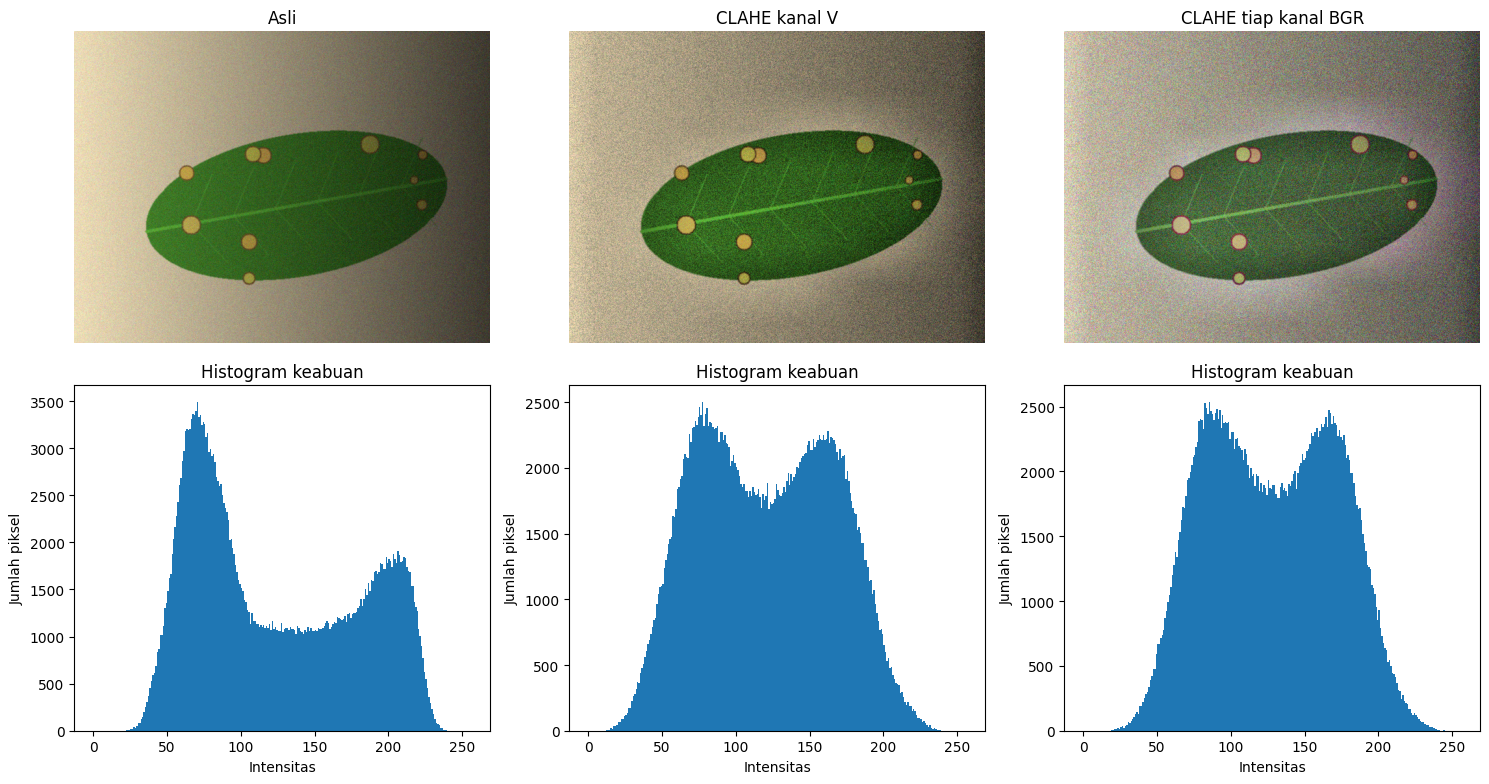

In [5]:
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

# Cara 1: terapkan CLAHE hanya pada kanal V dalam HSV
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
hsv_v = hsv.copy()
hsv_v[:, :, 2] = clahe.apply(hsv[:, :, 2])
via_v = cv2.cvtColor(hsv_v, cv2.COLOR_HSV2BGR)

# Cara 2: terapkan CLAHE secara terpisah pada kanal B, G, R
via_bgr = cv2.merge([
    clahe.apply(c) for c in cv2.split(img)
])

gray_v = cv2.cvtColor(via_v, cv2.COLOR_BGR2GRAY)
gray_bgr = cv2.cvtColor(via_bgr, cv2.COLOR_BGR2GRAY)

print("KB citra asli:",
      round(kontras_bercak(gray, md, mb), 2))
print("KB CLAHE kanal V:",
      round(kontras_bercak(gray_v, md, mb), 2))
print("KB CLAHE tiap kanal BGR:",
      round(kontras_bercak(gray_bgr, md, mb), 2))

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

perbandingan = [
    ("Asli", img),
    ("CLAHE kanal V", via_v),
    ("CLAHE tiap kanal BGR", via_bgr)
]

for i, (judul, citra) in enumerate(perbandingan):
    axes[0, i].imshow(cv2.cvtColor(citra, cv2.COLOR_BGR2RGB))
    axes[0, i].set_title(judul)
    axes[0, i].axis("off")

    g = cv2.cvtColor(citra, cv2.COLOR_BGR2GRAY)
    axes[1, i].hist(g.ravel(), bins=256, range=(0, 256))
    axes[1, i].set_title("Histogram keabuan")
    axes[1, i].set_xlabel("Intensitas")
    axes[1, i].set_ylabel("Jumlah piksel")

plt.tight_layout()
plt.savefig(
    os.path.join(HASIL, "b3_clahe_warna.png"),
    dpi=150, bbox_inches="tight"
)
plt.show()

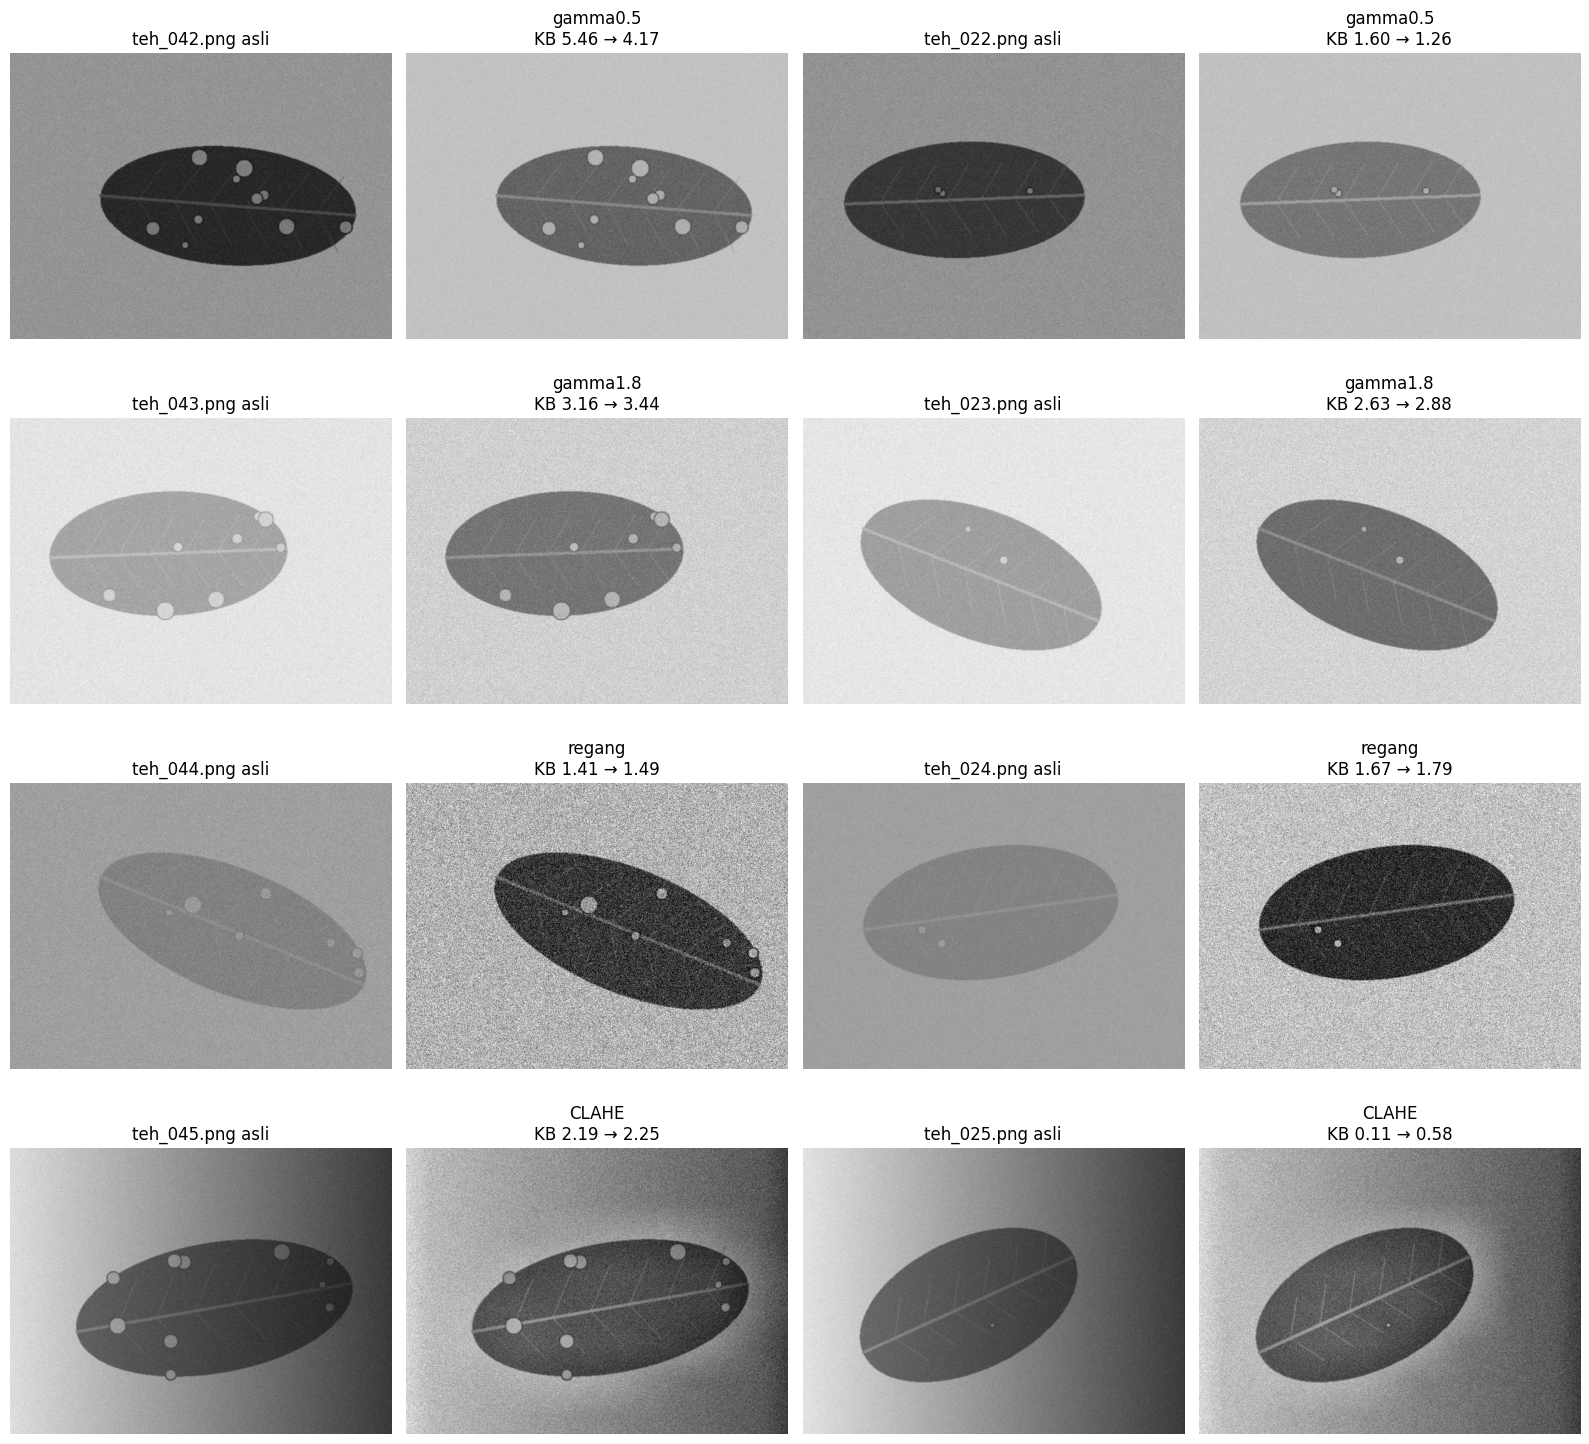

,Kondisi,Kelas,Citra,Metode,KB awal,KB sesudah,Perubahan KB
0,gelap,berat,teh_042.png,gamma0.5,5.46,4.17,-1.29
1,gelap,ringan,teh_022.png,gamma0.5,1.60,1.26,-0.33
2,terang,berat,teh_043.png,gamma1.8,3.16,3.44,0.28
3,terang,ringan,teh_023.png,gamma1.8,2.63,2.88,0.25
4,kontras rendah,berat,teh_044.png,regang,1.41,1.49,0.08
5,kontras rendah,ringan,teh_024.png,regang,1.67,1.79,0.12
6,bayangan,berat,teh_045.png,CLAHE,2.19,2.25,0.06
7,bayangan,ringan,teh_025.png,CLAHE,0.11,0.58,0.47


In [6]:
def perbaiki(gray, metode):
    if metode == "gamma0.5":
        return cv2.LUT(gray, gamma_lut(0.5))

    if metode == "gamma1.8":
        return cv2.LUT(gray, gamma_lut(1.8))

    if metode == "regang":
        lo, hi = np.percentile(gray, (2, 98))
        if hi <= lo:
            return gray.copy()
        return np.clip(
            (gray.astype(np.float32) - lo) / (hi - lo) * 255,
            0, 255
        ).astype(np.uint8)

    if metode == "CLAHE":
        return cv2.createCLAHE(
            clipLimit=2.0,
            tileGridSize=(8, 8)
        ).apply(gray)

    raise ValueError("Metode tidak dikenal: " + metode)


pasangan = [
    ("gelap", "teh_042.png", "teh_022.png", "gamma0.5"),
    ("terang", "teh_043.png", "teh_023.png", "gamma1.8"),
    ("kontras rendah", "teh_044.png", "teh_024.png", "regang"),
    ("bayangan", "teh_045.png", "teh_025.png", "CLAHE")
]

ringkasan = []

fig, axes = plt.subplots(4, 4, figsize=(16, 15))

for i, (kondisi, berat, ringan, metode) in enumerate(pasangan):
    for j, nama_file in enumerate([berat, ringan]):
        img_k = baca(os.path.join(DATA, "citra", nama_file))
        md_k = cv2.imread(
            os.path.join(DATA, "mask_daun", nama_file), 0
        )
        mb_k = cv2.imread(
            os.path.join(DATA, "mask_bercak", nama_file), 0
        )

        gray_k = cv2.cvtColor(img_k, cv2.COLOR_BGR2GRAY)
        hasil_k = perbaiki(gray_k, metode)

        kb_awal = kontras_bercak(gray_k, md_k, mb_k)
        kb_akhir = kontras_bercak(hasil_k, md_k, mb_k)

        ringkasan.append({
            "Kondisi": kondisi,
            "Kelas": "berat" if j == 0 else "ringan",
            "Citra": nama_file,
            "Metode": metode,
            "KB awal": round(kb_awal, 2),
            "KB sesudah": round(kb_akhir, 2),
            "Perubahan KB": round(kb_akhir - kb_awal, 2)
        })

        col_awal = j * 2
        axes[i, col_awal].imshow(gray_k, cmap="gray", vmin=0, vmax=255)
        axes[i, col_awal].set_title(f"{nama_file} asli")
        axes[i, col_awal].axis("off")

        axes[i, col_awal + 1].imshow(
            hasil_k, cmap="gray", vmin=0, vmax=255
        )
        axes[i, col_awal + 1].set_title(
            f"{metode}\nKB {kb_awal:.2f} → {kb_akhir:.2f}"
        )
        axes[i, col_awal + 1].axis("off")

plt.tight_layout()
plt.savefig(
    os.path.join(HASIL, "b3_sebelum_sesudah_4kondisi.png"),
    dpi=150, bbox_inches="tight"
)
plt.show()

tabel_per_kondisi = pd.DataFrame(ringkasan)
display(tabel_per_kondisi)

tabel_per_kondisi.to_csv(
    os.path.join(HASIL, "b3_perbaikan_4kondisi.csv"),
    index=False
)